# Updating temperature with the Nelson & Langer (1999) thermal model

This notebook shows how to update gas temperatures using the code that implements the Nelson and Langer heating and cooling model, apply it to tracer data, and compute how the updated temperature changes with each chemical abundance.

`update_temperatures_batch` advances one or more gas cells by a time step dt, holding the chemical abundances, density, and radiation field fixed. It solves the backward-Euler energy equation using Newton–Raphson, with a scalar fallback for cells that fail to converge in the batch.

- **temperature_update.py** provides `update_temperatures_batch`.

- **temperature_derivatives.py** provides `temperature_derivatives_batch`, which takes the updated temperature and computes its derivative with respect to each of the nine input abundances.

- **c/** contains the generated residual, Jacobian, and abundance derivatives, plus their batch wrappers. The batch solver and scalar fallback use the same C residual and Jacobian.

The notebook requires NumPy, SciPy, and Matplotlib. When a shared library is missing, its Python module builds it on import using gcc. The generated C sources are included, so you can run the notebook without installing jaco.

Use kelvin for temperature, seconds for dt, and cm⁻³ for n_H. Abundances are per H nucleus, pdv_work is in erg cm⁻³ s⁻¹, G_0 is in Habing units, and dv_dr is in s⁻¹.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from temperature_update import SPECIES, update_temperatures_batch
from temperature_derivatives import temperature_derivatives_batch

KYR = 3.15576e10  # seconds in a kyr

## Calling update_temperatures_batch

We first cover the basic inputs to the function and later we cover applying the function to tracer data. The Nelson model requires the abundances, per H nucleus, of nine species: H_2, H3+, He+, CH, OH, CO, C+, HCO+ and Mg+ (CH, OH and Mg+ stand for the composites CHx, OHx and M+ of Nelson & Langer). The electrons and the neutral C, O, He and Mg follow from charge neutrality and the elemental totals (`y`, `x_C,tot`, `x_O,tot` and `x_Mg,tot`), which default to the values of Nelson & Langer (1999) and can be given as keyword arguments. The initial temperature, the time step, the density and the abundances broadcast against each other, so each of them can be a number or an array with one value per cell. The other physical inputs are `A_V`, `tau_uv`, `G_0`, `dv_dr` and `pdv_work` which have default values if not set by the user. 

Below we set an example chemical state and some physical parameters to call `update_temperatures_batch`. It returns the new temperatures and the number of Newton iterations used.

In [2]:
example_state = {"H_2": 0.5, "H3+": 1e-9, "He+": 1e-9, "CH": 0.0, "OH": 0.0, "CO": 1e-6,   "C+": 4.5e-5, "HCO+": 0.0,  "Mg+": 5e-8}

T_initial = 60   # Initial temp.
dt        = 1e11 # Time step
n_H       = 1e3  # Density
A_V       = 0.3  # Visual extinction
tau_uv    = 0.69 # Optical depth

T_new, iterations = update_temperatures_batch(T_initial, dt, n_H, example_state, A_V=A_V, tau_uv=tau_uv)

print(f"T = {T_initial} K, n_H = {n_H:.1e} cm^-3, dt = {dt:.1e} s: T_new = {float(T_new):.4f} K ({iterations} Newton iterations)")

T = 60 K, n_H = 1.0e+03 cm^-3, dt = 1.0e+11 s: T_new = 39.3727 K (4 Newton iterations)


In the next cell we demonstrate repeated batched updates, using a fixed dt, to evolve initial temperatures 100 K and 5 K for three densities. All six cases advance together (one batched update per step). 

The result is compared to evolving the temperatures over the same time duration in a single step (open circles). The open circles differ from the lines when the whole duration is longer than the time it takes the gas to relax (one backward-Euler step that long is stable but only first-order accurate).

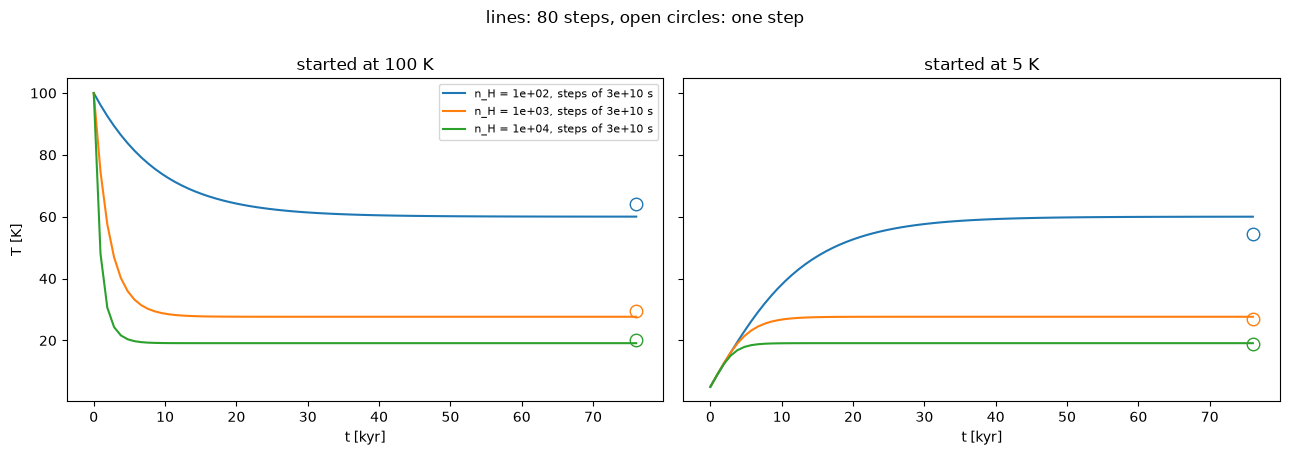

In [3]:
dt        = 3e10
n_steps   = 80
A_V       = 0.3  
tau_uv    = 0.69
T_starts  = np.array([100.0, 5.0])[:, None]
densities = np.array([1e2, 1e3, 1e4])[None, :]

# Evolve the initial temperatures.
T = np.broadcast_to(T_starts, (2, 3)).copy()
history = [T]
for _ in range(n_steps):
    T, _ = update_temperatures_batch(T, dt, densities, example_state, A_V=A_V, tau_uv=tau_uv)
    history.append(T)
history = np.array(history)

# Repeat the evolution in one time step.
t_kyr = dt * np.arange(n_steps + 1) / KYR
one_step, _ = update_temperatures_batch(T_starts, n_steps * dt, densities, example_state, A_V=A_V, tau_uv=tau_uv)

# Plot the results.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for i, (ax, T0) in enumerate(zip(axes, T_starts.ravel())):
    for j, (n, colour) in enumerate(zip(densities.ravel(), ("C0", "C1", "C2"))):
        ax.plot(t_kyr, history[:, i, j], colour, label=f"n_H = {n:.0e}, steps of {dt:.0e} s")
        ax.plot(t_kyr[-1], one_step[i, j], colour + "o", mfc="none", ms=9)
    ax.set(xlabel="t [kyr]", title=f"started at {T0:.0f} K")

axes[0].set_ylabel("T [K]"); axes[0].legend(fontsize=8)
fig.suptitle(f"lines: {n_steps} steps, open circles: one step", y=1.0)
plt.tight_layout()

## Computing temperature from tracer data.
In the next few cells, we use the Nelson model to evolve the temperature of a tracer. We first cover how tracer data can be used to make input data for the Nelson model and list the assumptions made in the process. Then we compare the Nelson temperature updates with the hydro temperature evolution in the tracer data. 


### Creating input data for the Nelson model from tracer data:

- **Chemical abundances:** these are read directly from the tracer data and are already per H nucleus.

- **Radiation:** The Nelson model requires three radiation related parameters: the unattenuated far UV field strength `G_0`, the visual extinction `A_V` and an optical depth `tau_uv`. We take `G_0` to be a constant 1.7 in Habing units (This is one Draine unit). `A_V` is set to the tracer `Av_pdfac` field. The optical depth is set by `tau_uv` = -ln(uv1 / UVREF1) where UVREF1 is taken from the tracer data's README.

- **PdV work:** the hydro compression rate is not in the tracer data, so it is estimated from the change of density between hydro steps, assuming an ideal gas: `pdv_work` = P dln(n_H)/dt, with P = n_tot k T and n_tot the sum of all species.

- **Velocity gradient:** One of the Nelson cooling terms requires a velocity gradient which is not in the tracer data. So `dv_dr` is left at its default of 1 km/s/pc.

In [10]:
# This cell assumes a tracer data file is located at `path` and the follwing variables are taken from the associated metadata.
path = "data/piecewise_constant/R0.025_M6_trace_cells.npy"
tracer, rows_per_tracer, rows_per_segment = 0, 531, 5
UVREF1 = 0.64282316

# Get the physical parameters.
block = np.asarray(np.load(path, mmap_mode="r")[tracer * rows_per_tracer:(tracer + 1) * rows_per_tracer])
t, n_H, T_hydro, Av_pdfac, uv1 = block[:, 1], block[:, 2], block[:, 3], block[:, 5], block[:, 6]
tau_uv_tracer = np.maximum(-np.log(uv1 / UVREF1), 0.0)
G_0 = 1.7
K_B = 1.380649e-16 # Boltzman in cgs

# Get the chemical abundances.
columns = ["C", "C+", "CH", "CO", "H_2", "H3+", "HCO+", "He", "He+", "Mg", "Mg+", "O", "OH", "e-"]
x = dict(zip(columns, block[:, 9:23].T))
species = {s: x[s] for s in SPECIES}
n_species_total = block[:, 9:23].sum(axis=1)
totals = {
    "y":        (x["He"] + x["He+"])[0],
    "x_C,tot":  (x["C"] + x["C+"] + x["CH"] + x["CO"] + x["HCO+"])[0],
    "x_O,tot":  (x["O"] + x["OH"] + x["CO"] + x["HCO+"])[0],
    "x_Mg,tot": (x["Mg"] + x["Mg+"])[0]
}

# The hydro segments: their first rows, and the compression rate d ln(n_H) / dt across each.
knots = np.arange(0, rows_per_tracer, rows_per_segment)
segment_dt = np.diff(t[knots])
compression_rate = np.log(n_H[knots[1:]] / n_H[knots[:-1]]) / segment_dt

In the next cell, we evolve the temperature along the whole tracer using the initial hydro temperature as an initial state.

In [5]:
# (1) The update along the tracer in steps of one row, with the environment of the segment's first row.
T_evolved = [T_hydro[0]]

for i in range(rows_per_tracer - 1):
    first = knots[i // rows_per_segment]
    pdv_work = n_species_total[i] * n_H[first] * K_B * T_evolved[-1] * compression_rate[i // rows_per_segment]
    
    T_next, _ = update_temperatures_batch(
        T_evolved[-1], t[i + 1] - t[i], n_H[first], {s: v[i] for s, v in species.items()},
        pdv_work=pdv_work, G_0=G_0, A_V=Av_pdfac[first], tau_uv=tau_uv_tracer[first], **totals
    )
    T_evolved.append(float(T_next))

T_evolved = np.array(T_evolved)

In the next cell, we evolve the temperature over a single hydro step (0.25 kyr) from the initial hydro temperature of each step.

In [6]:
# (2) One hydro segment from the hydro temperature at the start of each segment, all segments in one batched call.
start = knots[:-1]
T_segment, _ = update_temperatures_batch(
    T_hydro[start], segment_dt, n_H[start], {s: v[start] for s, v in species.items()},
    pdv_work=n_species_total[start] * n_H[start] * K_B * T_hydro[start] * compression_rate,
    G_0=G_0, A_V=Av_pdfac[start], tau_uv=tau_uv_tracer[start], **totals
)

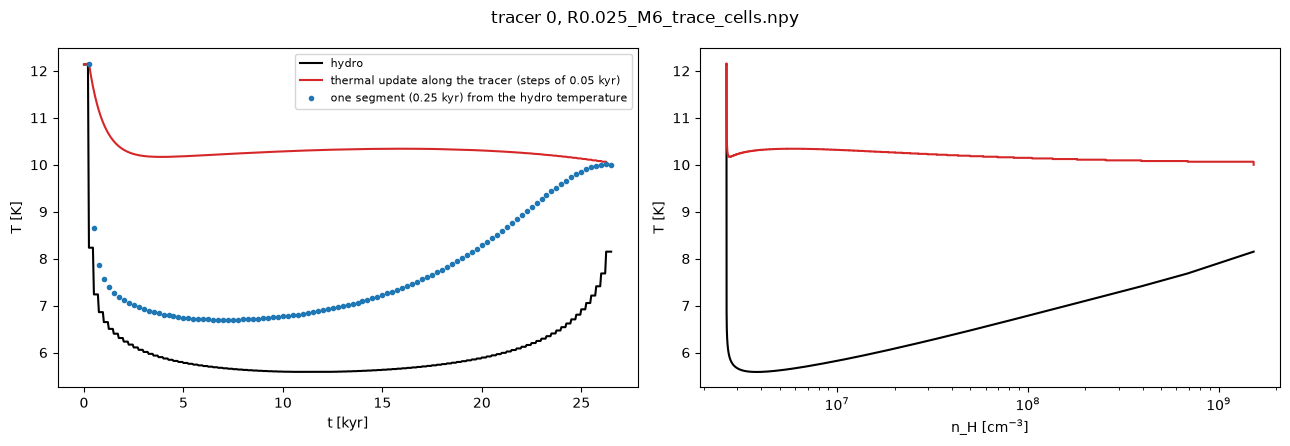

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(t / KYR, T_hydro, "k", label="hydro")
axes[0].plot(t / KYR, T_evolved, "C3", label="thermal update along the tracer (steps of 0.05 kyr)")
axes[0].plot(t[knots[1:]] / KYR, T_segment, "C0.", label="one segment (0.25 kyr) from the hydro temperature")
axes[0].set(xlabel="t [kyr]", ylabel="T [K]")
axes[0].legend(fontsize=8)

axes[1].plot(n_H, T_hydro, "k")
axes[1].plot(n_H, T_evolved, "C3")
axes[1].set(xscale="log", xlabel="n_H [cm$^{-3}$]", ylabel="T [K]")
fig.suptitle(f"tracer {tracer}, {path.split('/')[-1]}")
plt.tight_layout()

## Derivatives with respect to the chemical abundances

Once `T_new` is computed, `temperature_derivatives_batch` returns the derivative of `T_new` with respect to the abundance of each of the nine species, in every cell, in K per unit abundance (per H nucleus). The derivatives are computed by holding the initial temperature, the time step, the elemental totals and the other inputs fixed, so changing an abundance also changes the neutral C, O, He and Mg and the electrons through the conservation laws.

A note on how the code computes this: the Newton iterations are not differentiated to compute the derivatives. Instead, a combination of the implicit function theorem and the chain rule is used to compute them. Specifically, at the solution, the backward Euler residual F (which depends on X = (u, T_new) and chemical abundances x) is zero. So by the implicit function theorem, X should depend on x and F(X(x), x) = 0. Differentiating with respect to x we get dX/dx = -J^-1 dF/dx, where J is the derivative of F with respect to X. J is computed using the same functions used by the Newton iterations to find `T_new`. The remaining dF/dx is computed by auxiliary functions that were generated using jaco.

The first cell below computes the derivatives for the first example, and checks them by re-solving with a changed abundance. The second computes them for many cells at once.

In [8]:
inputs = dict(T=60.0, dt=1e11, n_H=1e3, species=example_state, A_V=0.3, tau_uv=0.69)
T_new, _ = update_temperatures_batch(**inputs, rtol=1e-14)
derivatives = temperature_derivatives_batch(**inputs, T_new=T_new)

# Check by re-solving with one abundance changed by a small step (uses forward difference if abundance is zero).
def re_solved_derivative(s, step=1e-10):
    x = example_state[s]
    lower = x - step if x > 0 else x
    T_plus, _ = update_temperatures_batch(**{**inputs, "species": {**example_state, s: x + step}}, rtol=1e-14)
    T_minus, _ = update_temperatures_batch(**{**inputs, "species": {**example_state, s: lower}}, rtol=1e-14)
    return float(T_plus - T_minus) / (x + step - lower)

print(f"T = {inputs['T']:.0f} K, n_H = {inputs['n_H']:.0e} cm^-3, dt = {inputs['dt']:.0e} s: T_new = {float(T_new):.4f} K")
print(f"{'species':>8s} {'abundance':>10s} {'dT_new/dx [K]':>14s} {'re-solved [K]':>14s} {'rel. diff.':>11s}")
for s in SPECIES:
    derivative = float(derivatives[s]) 
    re_solved = re_solved_derivative(s)
    print(f"{s:>8s} {example_state[s]:10.1e} {derivative:14.4e} {re_solved:14.4e} {abs(derivative / re_solved - 1):11.1e}")

T = 60 K, n_H = 1e+03 cm^-3, dt = 1e+11 s: T_new = 39.3727 K
 species  abundance  dT_new/dx [K]  re-solved [K]  rel. diff.
     H_2    5.0e-01     3.1159e+01     3.1159e+01     4.5e-07
     H3+    1.0e-09     1.2949e+03     1.2949e+03     2.9e-09
     He+    1.0e-09     1.2841e+03     1.2841e+03     3.7e-09
      CH    0.0e+00     1.0369e+04     1.0369e+04     1.0e-06
      OH    0.0e+00     5.9903e+02     5.9903e+02     6.8e-08
      CO    1.0e-06     1.0957e+04     1.0957e+04     1.5e-09
      C+    4.5e-05    -2.1378e+05    -2.1378e+05     1.0e-11
    HCO+    0.0e+00     1.2241e+04     1.2241e+04     1.1e-06
     Mg+    5.0e-08     1.2841e+03     1.2841e+03     3.7e-09


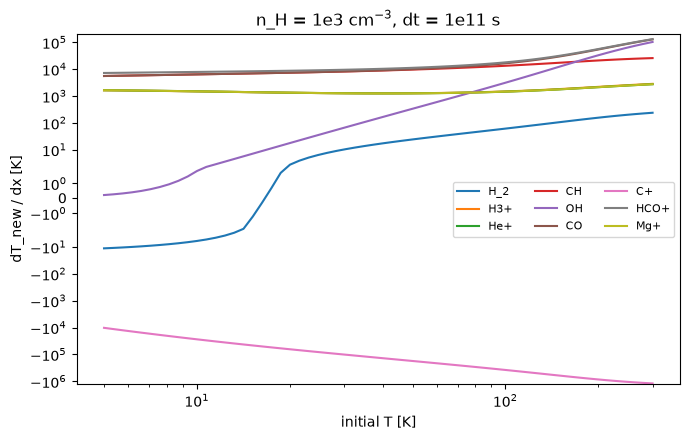

In [9]:
# The same for many cells at once: initial temperatures from 5 to 300 K, one batched call for T_new and one for the derivatives.
T_initial = np.geomspace(5, 300, 60)
cells = dict(T=T_initial, dt=1e11, n_H=1e3, species=example_state, A_V=0.3, tau_uv=0.69)
T_new, _ = update_temperatures_batch(**cells)
derivatives = temperature_derivatives_batch(**cells, T_new=T_new)

fig, ax = plt.subplots(figsize=(7, 4.5))
for s in SPECIES:
    ax.plot(T_initial, derivatives[s], label=s)
ax.set(xscale="log", yscale="symlog", xlabel="initial T [K]", ylabel="dT_new / dx [K]")
ax.set_title("n_H = 1e3 cm$^{-3}$, dt = 1e11 s")
ax.legend(fontsize=8, ncol=3)
plt.tight_layout()